# M033: did the mouse learn the deletion sessions, or just shake the lever?

**Protocol recap (sessions 4-32)**

| sessions | phase | what changed |
|---|---|---|
| 4-6 | Intro | first exposure to the position task: exert a target force (ring of ~8-12 g, any direction) |
| 7-17 | Harder preset | longer hold or narrower force range (same ring LUT) |
| 18-22 | Deletion 1 | the biased (pull / posterior) part of the ring is no longer rewarded |
| 23-24 | Deletion 2 | larger non-rewarded area |
| 25 | Deletion 3 | larger again |
| 26-28 | All pull removed | every rewarded force now requires pushing forward (anterior half only) |
| 29-32 | Pull removed + wider range | as above, slightly wider force range |

**The question.** Even in the last sessions the force trajectories are full of pulls toward the
mouse. Is the mouse doing anything targeted, or is it shaking the lever and getting rewarded by
chance?

**How the task actually pays out (checked against the lickport traces).** The LUT gives a lickport
speed for every (Left-Right, Posterior-Anterior) force. When the force enters the high-speed ring,
the lickport shoots forward within ~100 ms. When the force leaves, it drops back to its start position. A
reward happens only when the force stays in the ring long enough for the lickport to reach (and
hold) the end. So what matters is **entering the rewarded zone and staying there**, not time
accumulated across many brief visits.

**Important epoch caveat (section 3).** The lickport reaches its end position ~0.5 s *before* the
`threshold crossing` event. The usual "response epoch" (go -> threshold crossing) therefore ends with ~0.5 s
in which the spout is already in front of the mouse, and in late sessions the mouse makes a strong pull
toward itself during exactly that window. Those pulls happen *after* the reward was earned, so they cannot be
what earned it. Most analyses below therefore use the **earning window = go -> lickport arrival**.

**Figures in this notebook**
1. The reward map (LUT) per phase: what was being asked.
2. Time to reward, reward rate and quiescence per session: your original idea.
3. The pull after the lickport arrives: threshold-aligned force, and how much of the "pulling" is post-arrival.
4. Force *direction* and *magnitude* occupancy per session vs. which directions were rewarded.
5. Time budget: how much the mouse pushes vs. pulls vs. rests, and how often it makes each type of excursion.
6. **Rotation null**: are the mouse's force directions better than random directions? This tests the "random shaking" idea directly.
7. First movement after the go cue, and the direction of the force bout that earned the reward.
8. Rewarded-zone bouts: attempts per reward, hold durations, and whether rewards follow a pull (rebound).
9. Example force trajectories around reward, early vs. late.
10. Within-session dynamics (does the mouse adapt over the course of a session?).
11. Summary table + trend statistics across the deletion sessions.

Force traces are gaussian-filtered (sigma = 3 ms), the same preprocessing as in the block figures.

In [1]:
from pathlib import Path
import sys

repo_root = next((parent for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (parent / 'ndnf_pipeline').exists()), None)
if repo_root is None:
    raise RuntimeError('Could not locate the repository root')
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
import datajoint as dj
dj.config.load(str(repo_root / 'dj_local_conf.json'))
dj.conn()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from scipy.ndimage import gaussian_filter1d
from scipy.stats import spearmanr
from ndnf_pipeline import experiment
from ndnf_pipeline.plot import behavior_plots as bp

subject_id = 'M033'
sessions = list(range(4, 33))

# ---- analysis parameters ----
FILTER_SIGMA_MS = 3.0   # gaussian smoothing of the force traces
DOWNSAMPLE = 5          # keep every 5th sample after smoothing (1 kHz -> 200 Hz) to save memory
FS = 1000 / DOWNSAMPLE  # Hz, after downsampling
ACTIVE_G = 3.0          # |force| above this counts as 'active' (otherwise resting / near zero)
EXCURSION_G = 5.0       # |force| above this counts as a deliberate excursion (pull / push / lateral)
ZONE_SPEED = 0.5        # LUT value (normalised lickport speed) above which the force is 'in the rewarded zone'
PULL_LOOKBACK_S = 0.3   # window before a zone entry in which we look for a preceding pull (rebound test)
BOUT_MERGE_S = 0.05     # zone bouts separated by a gap shorter than this are merged (avoids edge flicker)
N_ROTATIONS = 24        # rotations for the random-direction null (every 15 deg)

# ---- protocol phases ----
PHASES = [
    ('Intro',                     range(4, 7)),
    ('Harder preset',             range(7, 18)),
    ('Deletion 1',                range(18, 23)),
    ('Deletion 2',                range(23, 25)),
    ('Deletion 3',                range(25, 26)),
    ('All pull removed',          range(26, 29)),
    ('Pull removed, wider range', range(29, 33)),
]
_del_cols = plt.cm.OrRd(np.linspace(0.45, 0.95, 5))  # progressively harsher deletions -> darker
PHASE_COLORS = dict(zip([p for p, _ in PHASES], ['#a6a6a6', '#5a5a5a', *_del_cols]))
session_phase = {s: p for p, rng in PHASES for s in rng}
session_color = {s: PHASE_COLORS[session_phase[s]] for s in sessions}
DIR_COLORS = {'pull': '#7b3294', 'lateral': '#bababa', 'push': '#1b7837'}

fig_dir = repo_root / 'Notebooks' / 'figures' / f'{subject_id}_deletion'
fig_dir.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    fig.savefig(fig_dir / f'{subject_id}_{name}.png', dpi=300, bbox_inches='tight')

def style(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

def mark_phases(ax, label=True, y=1.0):
    """Light vertical separators between protocol phases on a session-number x axis."""
    for p, rng in PHASES[1:]:
        ax.axvline(rng[0] - 0.5, color='0.85', lw=0.8, zorder=0)
    ax.axvline(17.5, color='0.4', lw=1, ls='--', zorder=0)  # deletion starts
    if label:
        for p, rng in PHASES:
            ax.text((rng[0] + rng[-1]) / 2, y, p, transform=ax.get_xaxis_transform(), ha='center', va='bottom',
                    fontsize=7, color=PHASE_COLORS[p], rotation=0 if len(rng) > 2 else 30)
    ax.set_xlim(sessions[0] - 0.7, sessions[-1] + 0.7)

def phase_legend(ax, **kw):
    handles = [Line2D([0], [0], marker='o', ls='None', color=PHASE_COLORS[p], label=f'{p} (s{rng[0]}-{rng[-1]})')
               for p, rng in PHASES]
    ax.legend(handles=handles, frameon=False, fontsize=7, **kw)

C:\NDNF-pipeline\.venv\Lib\site-packages\datajoint\plugin.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources  # requires setuptools<82


[2026-11-18 15:23:37,235][INFO]: DataJoint is configured from C:\NDNF-pipeline\dj_local_conf.json


[2026-11-18 15:23:37,328][INFO]: DataJoint 0.14.9 connected to rozmar@datajoint.ndnf.koki.hun-ren.hu:3306


## Load data
For every block: the LUT (normalised to X = Left-Right, Y = Posterior-Anterior; negative PA = pulling
toward the mouse). For every rewarded trial: the response-epoch force trace (go -> threshold crossing),
gaussian-filtered and downsampled to 200 Hz, and the **lickport arrival time**, i.e. the start of the
lickport's final stay at its end position. Takes about a minute.

In [3]:
def block_lut(key):
    tsid, lut = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id', 'target_force_lut')
    fad, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, key['subject_id'], key['session'], tsid)
    L, ext, _, _ = bp._normalize_lut(lut, fad, lr_idx, pa_idx, lr_sign, pa_sign)  # L is [LR, PA]
    return L, ext, (lr_idx, pa_idx, lr_sign, pa_sign)


def lut_lookup(L, ext, lr, pa):
    """Nearest-bin LUT value (normalised lickport speed) for force samples; out-of-range forces use the edge bin."""
    n_lr, n_pa = L.shape
    i = np.clip(np.rint((lr - ext[0]) / (ext[1] - ext[0]) * (n_lr - 1)).astype(int), 0, n_lr - 1)
    j = np.clip(np.rint((pa - ext[2]) / (ext[3] - ext[2]) * (n_pa - 1)).astype(int), 0, n_pa - 1)
    return L[i, j]


def lickport_arrival(t, v, tol_mm=0.05):
    """Trial-relative time at which the lickport starts its final stay at the end position."""
    t, v = np.asarray(t, float), np.asarray(v, float)
    if len(v) == 0:
        return np.nan
    at_end = v >= v.max() - tol_mm
    i = len(v) - 1
    while i > 0 and at_end[i - 1]:
        i -= 1
    return t[i]


def load_block(key):
    L, ext, axes = block_lut(key)
    lp_trials, lp_t, lp_v = (experiment.TrialRewardPortPosition() * experiment.BehaviorTrial() & key).fetch(
        'trial', 'reward_port_position_time', 'reward_port_position_values')
    arrival = {int(tr): lickport_arrival(t, v) for tr, t, v in zip(lp_trials, lp_t, lp_v)}
    trials, times = (experiment.TrialForceTrace() * experiment.BehaviorTrial() & key).fetch(
        'trial', 'force_trace_time', order_by='trial')
    tr0, f0 = (experiment.TrialForceTrace.TrialForceAxis() * experiment.BehaviorTrial() & key
               & {'force_axis_idx': 0}).fetch('trial', 'force_trace_value', order_by='trial')
    tr1, f1 = (experiment.TrialForceTrace.TrialForceAxis() * experiment.BehaviorTrial() & key
               & {'force_axis_idx': 1}).fetch('trial', 'force_trace_value', order_by='trial')
    assert np.array_equal(trials, tr0) and np.array_equal(trials, tr1)
    # same baseline convention as the block figures: subtract the block median of each raw axis
    b0, b1 = np.median(np.concatenate(f0)), np.median(np.concatenate(f1))
    lr_all, pa_all = bp._lr_pa_traces([f - b0 for f in f0], [f - b1 for f in f1], *axes)

    go = bp._event_time_by_trial(experiment, key, 'go')
    thr = bp._event_time_by_trial(experiment, key, 'threshold crossing')
    hits = set((experiment.BehaviorTrial() & key & {'outcome': 'hit'}).fetch('trial').astype(int))  # misses (1000 s timeouts) also log a threshold crossing
    out = []
    for trial, t, lr, pa in zip(trials, times, lr_all, pa_all):
        trial = int(trial)
        if trial not in hits or trial not in go or trial not in thr:  # misses / unfinished last trial
            continue
        t = np.asarray(t, float)
        sigma = FILTER_SIGMA_MS / 1000 / np.median(np.diff(t))
        lr = gaussian_filter1d(np.asarray(lr, float), sigma)
        pa = gaussian_filter1d(np.asarray(pa, float), sigma)
        m = (t >= go[trial]) & (t < thr[trial])
        lr_d, pa_d = lr[m][::DOWNSAMPLE], pa[m][::DOWNSAMPLE]
        arr = arrival.get(trial, np.nan)
        arr = thr[trial] - 0.5 if not np.isfinite(arr) else arr  # fallback: typical lag
        n_pre = int(np.clip(round((arr - go[trial]) * FS), 1, len(lr_d)))  # samples go -> arrival
        out.append(dict(session=key['session'], block=key['block'], trial=trial,
                        quiescence=go[trial], t2r=thr[trial] - go[trial], arrival_lag=thr[trial] - arr,
                        lr=lr_d, pa=pa_d, n_pre=n_pre))
    return out, (L, ext)


resp, luts, block_info = [], {}, []
for b in (experiment.Block() & {'subject_id': subject_id} & f'session between {sessions[0]} and {sessions[-1]}').fetch(
        'KEY', 'block_start_time', 'block_end_time', as_dict=True, order_by='session, block'):
    key = {k: b[k] for k in ('subject_id', 'session', 'block')}
    trials_b, luts[(b['session'], b['block'])] = load_block(key)
    resp.extend(trials_b)
    block_info.append(dict(session=b['session'], block=b['block'],
                           duration_s=float(b['block_end_time']) - float(b['block_start_time']),
                           n_rewards=len(trials_b)))
    print(f"s{b['session']} b{b['block']}: {len(trials_b)} rewarded trials", end=' | ')

block_info = pd.DataFrame(block_info)
session_lut = {s: luts[max(k for k in luts if k[0] == s)] for s in sessions}  # last block's LUT per session
print('\nloaded', len(resp), 'rewarded trials')

s4 b0: 75 rewarded trials

 | 

s5 b0: 28 rewarded trials

 | 

s5 b1: 39 rewarded trials

 | 

... (81 outputs left out)

 | 


loaded

1500

rewarded trials

### Shared helpers: direction, excursions, rewarded-zone bouts
* **Bearing** of a force sample: 0 deg = pure pull toward the mouse (posterior), +/-180 deg = pure push (anterior),
  +90 deg = right, -90 deg = left. With this convention the deleted region sits in the **centre** of every heatmap.
* **Sector**: pull = within 45 deg of straight back, push = within 45 deg of straight forward, lateral = the rest.
* **Excursion**: a contiguous run with |F| >= 5 g, classified by the bearing at its peak.
* **Zone bout**: a contiguous run in which the force is in the rewarded zone (LUT speed >= 0.5). Runs separated
  by gaps < 50 ms are merged. The last bout before lickport arrival is the one that produced the reward.

Everything computed in this cell uses the **earning window (go -> lickport arrival)**. `pre(r)` returns that part
of a trial; `post(r)` returns the post-arrival remainder (arrival -> threshold crossing).

In [4]:
def bearing(lr, pa):
    return np.degrees(np.arctan2(lr, -pa))


def sector(b):
    a = np.abs(b)
    return np.where(a <= 45, 'pull', np.where(a >= 135, 'push', 'lateral'))


def runs(mask, merge_gap=0):
    d = np.diff(np.concatenate([[0], mask.astype(int), [0]]))
    s, e = np.flatnonzero(d == 1), np.flatnonzero(d == -1)  # starts, ends (exclusive)
    if merge_gap and len(s) > 1:
        keep = np.concatenate([[True], (s[1:] - e[:-1]) >= merge_gap])
        s, e = s[keep], np.concatenate([e[:-1][keep[1:]], e[-1:]])
    return s, e


def pre(r):
    return r['lr'][:r['n_pre']], r['pa'][:r['n_pre']]


def post(r):
    return r['lr'][r['n_pre']:], r['pa'][r['n_pre']:]


rotations = np.deg2rad(np.arange(0, 360, 360 / N_ROTATIONS))
lookback = int(PULL_LOOKBACK_S * FS)
merge_gap = int(BOUT_MERGE_S * FS)

trial_rows, bout_rows = [], []
for r in resp:
    L, ext = luts[(r['session'], r['block'])]
    lr, pa = pre(r)
    mag, bear = np.hypot(lr, pa), bearing(lr, pa)
    v = lut_lookup(L, ext, lr, pa)
    active = mag >= ACTIVE_G
    sec = sector(bear)

    # excursions (|F| >= 5 g), classified at their peak
    es, ee = runs(mag >= EXCURSION_G)
    exc_dirs = [sec[s + np.argmax(mag[s:e])] for s, e in zip(es, ee)]
    first_bear = bear[es[0] + np.argmax(mag[es[0]:ee[0]])] if len(es) else np.nan

    # random-direction null: rotate the whole trial trajectory, keep magnitude and timing
    null = [lut_lookup(L, ext, lr * np.cos(a) - pa * np.sin(a), lr * np.sin(a) + pa * np.cos(a)).sum() for a in rotations]

    # rewarded-zone bouts
    zs, ze = runs(v >= ZONE_SPEED, merge_gap)
    for k, (s, e) in enumerate(zip(zs, ze)):
        bout_rows.append(dict(session=r['session'], trial=r['trial'], rewarded=(k == len(zs) - 1),
                              duration_ms=(e - s) / FS * 1000,
                              bearing=bearing(lr[s:e].mean(), pa[s:e].mean()),
                              pull_before=bool((pa[max(0, s - lookback):s] < -EXCURSION_G).any())))

    plr, ppa = post(r)
    pmag, psec = np.hypot(plr, ppa), sector(bearing(plr, ppa))
    trial_rows.append(dict(
        session=r['session'], block=r['block'], trial=r['trial'], phase=session_phase[r['session']],
        t2r=r['t2r'], quiescence=r['quiescence'], arrival_lag=r['arrival_lag'], n=len(v),
        n_post=len(plr), n_pull_post=((pmag >= ACTIVE_G) & (psec == 'pull')).sum(),
        min_pa_post=ppa.min() if len(ppa) else np.nan,
        n_active=active.sum(), n_pull=(active & (sec == 'pull')).sum(),
        n_push=(active & (sec == 'push')).sum(), n_lateral=(active & (sec == 'lateral')).sum(),
        exc_pull=exc_dirs.count('pull'), exc_push=exc_dirs.count('push'), exc_lateral=exc_dirs.count('lateral'),
        first_bearing=first_bear, v_sum=v.sum(), null_sums=np.array(null), n_bouts=len(zs)))

trials_df = pd.DataFrame(trial_rows)
bouts_df = pd.DataFrame(bout_rows)
trials_df.head()

,session,block,trial,phase,t2r,quiescence,arrival_lag,n,n_post,n_pull_post,...,n_pull,n_push,n_lateral,exc_pull,exc_push,exc_lateral,first_bearing,v_sum,null_sums,n_bouts
0,4,0,0,Intro,1.96000,0.41600,0.800000,232,160,83,...,29,20,133,2,1,2,-46.961499,116.623323,"[116.62332326173782, 116.65835427562706, 115.9...",3
1,4,0,1,Intro,13.66198,2.48602,0.549984,2622,111,0,...,0,110,41,0,4,2,75.351523,108.389843,"[108.38984266726766, 108.87924605910666, 107.7...",9
2,4,0,2,Intro,5.31600,0.71600,0.592000,945,119,0,...,0,149,30,0,4,0,-140.854661,209.334421,"[209.33442125248257, 206.99644623103086, 206.8...",5
3,4,0,3,Intro,17.62400,0.86400,0.572000,3410,115,0,...,5,169,16,0,6,2,-168.844901,164.342861,"[164.3428608700633, 167.38060025242157, 165.36...",6
4,4,0,4,Intro,12.52202,3.35398,0.598016,2385,120,0,...,0,382,43,0,6,1,-160.674838,619.375213,"[619.3752130257199, 623.9616328335833, 629.071...",6


## 1. What was being asked: the reward map per phase
Lickport speed for every force (yellow = fast = rewarded). One representative session per phase.
The rewarded ring sits at roughly the radii marked below. From session 18 the pull side is carved out
step by step, until from s26 only the anterior (push) half pays.

rewarded ring (LUT >= 0.5): 4.7 - 14.0 g, peak at 6.6 g

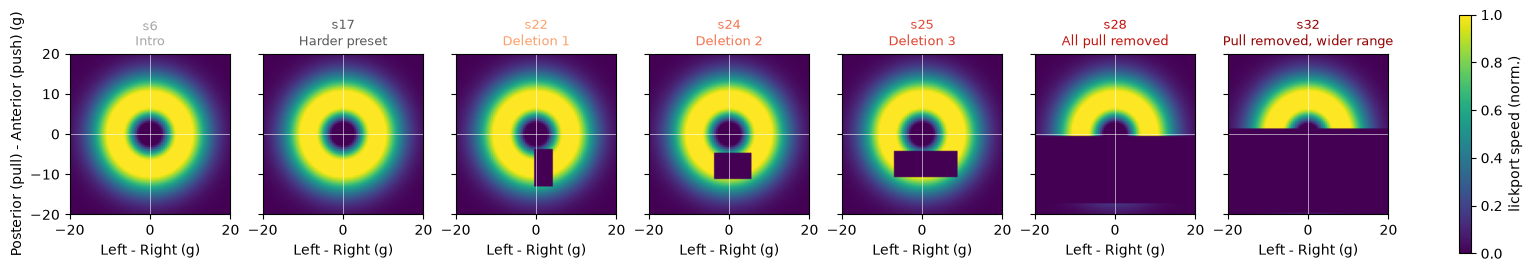

In [5]:
# ring geometry from the pre-deletion LUT (along the +LR axis)
L17, ext17 = session_lut[17]
r_axis = np.linspace(0, ext17[1], 400)
ring_speed = lut_lookup(L17, ext17, r_axis, np.zeros_like(r_axis))
ring_r_in, ring_r_out = r_axis[ring_speed >= ZONE_SPEED][[0, -1]]
ring_r_peak = r_axis[np.argmax(ring_speed)]
print(f'rewarded ring (LUT >= {ZONE_SPEED}): {ring_r_in:.1f} - {ring_r_out:.1f} g, peak at {ring_r_peak:.1f} g')

rep_sessions = [6, 17, 22, 24, 25, 28, 32]
lim = 20
fig, axes = plt.subplots(1, len(rep_sessions), figsize=(2.6 * len(rep_sessions), 3.1), sharey=True)
for ax, s in zip(axes, rep_sessions):
    L, ext = session_lut[s]
    im = ax.imshow(L.T, origin='lower', extent=ext, cmap='viridis', vmin=0, vmax=1)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.axhline(0, color='w', lw=0.4); ax.axvline(0, color='w', lw=0.4)
    ax.set_title(f's{s}\n{session_phase[s]}', fontsize=9, color=session_color[s])
    ax.set_xlabel('Left - Right (g)')
axes[0].set_ylabel('Posterior (pull) - Anterior (push) (g)')
fig.colorbar(im, ax=axes, fraction=0.015, label='lickport speed (norm.)')
savefig(fig, '01_lut_per_phase')
plt.show()

## 2. Time to reward, reward rate, quiescence
(a) every rewarded trial (dot) and the session median (black). Log scale.
(b) rewards per minute of session time, which includes both quiescence and response.
(c) median quiescence duration (trial start -> go), showing whether waiting still also got harder.

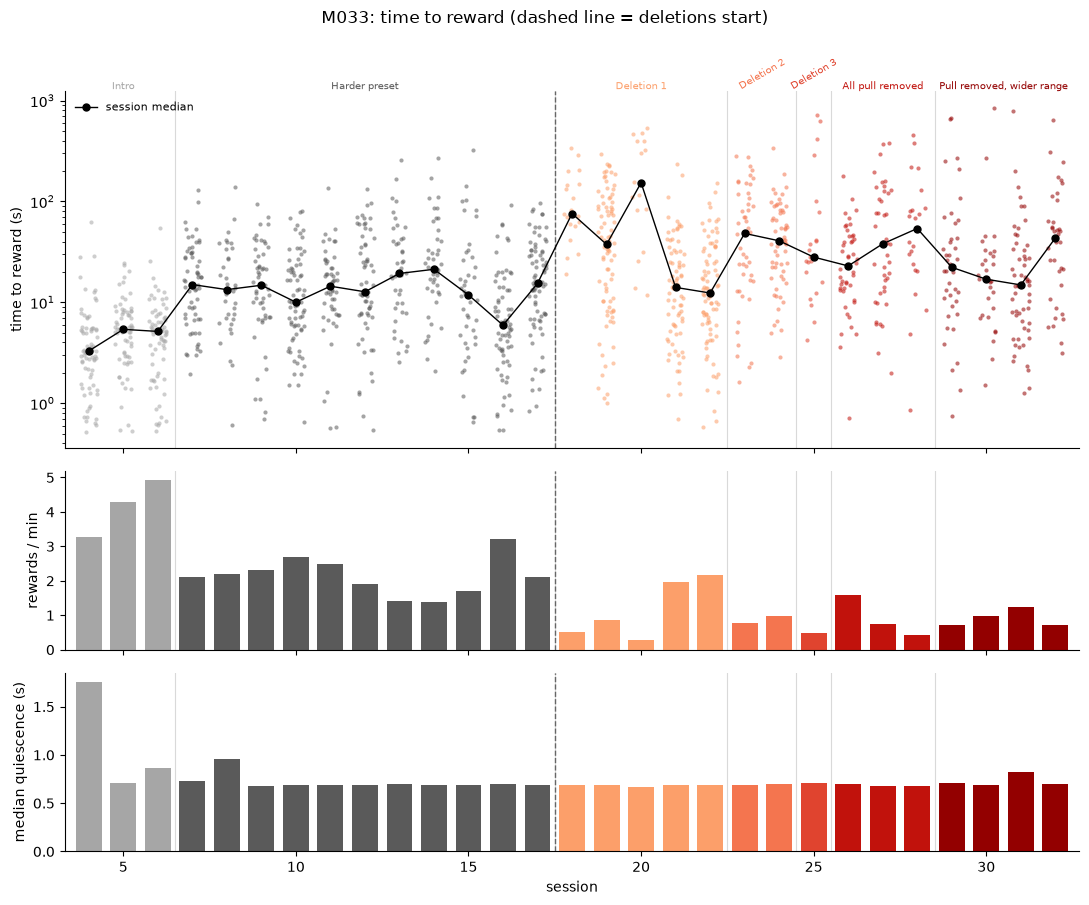

In [6]:
sess = trials_df.groupby('session').agg(t2r_med=('t2r', 'median'), quiescence_med=('quiescence', 'median'),
                                        n_rewards=('trial', 'size')).reindex(sessions)
sess['duration_min'] = block_info.groupby('session')['duration_s'].sum().reindex(sessions) / 60
sess['rewards_per_min'] = sess['n_rewards'] / sess['duration_min']

rng = np.random.default_rng(0)
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, gridspec_kw=dict(height_ratios=[2, 1, 1]))
ax = axes[0]
for s, g in trials_df.groupby('session'):
    ax.scatter(s + rng.uniform(-0.25, 0.25, len(g)), g['t2r'], s=9, color=session_color[s], alpha=0.55, lw=0)
ax.plot(sess.index, sess['t2r_med'], 'o-', color='k', ms=5, lw=1, label='session median')
ax.set_yscale('log'); ax.set_ylabel('time to reward (s)')
ax.legend(frameon=False, loc='upper left', fontsize=8)
mark_phases(ax)

ax = axes[1]
ax.bar(sess.index, sess['rewards_per_min'], color=[session_color[s] for s in sessions], width=0.75)
ax.set_ylabel('rewards / min'); mark_phases(ax, label=False)

ax = axes[2]
ax.bar(sess.index, sess['quiescence_med'], color=[session_color[s] for s in sessions], width=0.75)
ax.set_ylabel('median quiescence (s)'); ax.set_xlabel('session')
mark_phases(ax, label=False)
for a in axes: style(a)
fig.suptitle(f'{subject_id}: time to reward (dashed line = deletions start)', y=1.0)
fig.tight_layout()
savefig(fig, '02_time_to_reward')
plt.show()

## 3. The pull after the lickport arrives
The lickport's final arrival at the end position precedes the `threshold crossing` event by ~0.5 s in every
session. The mouse already has the spout in front of it during that time.
* **(a)** distribution of that lag per session.
* **(b)** mean Posterior-Anterior force aligned to threshold crossing, per phase (mean +/- SEM across trials). The
  dotted line marks the median lickport arrival. Negative = pulling toward the mouse.
* **(c)** of all pulling time in the classic response epoch (go -> threshold crossing), the share that falls
  **after** lickport arrival. By *time* this is modest (~5-12 % in the deletion sessions), but these are the
  largest pulls of the trial (-10 to -20 g, see b) and they occur on nearly every trial. In a trajectory plot every
  trial therefore ends with a long excursion toward the mouse, which makes the plot look pull-dominated.

The post-arrival pull looks like a consummatory / reaching movement toward the arrived spout, not an attempt to
move the lickport. It is a large part of why the late-session trajectory plots still look pull-heavy, and it should be
excluded when asking what the mouse does *to earn* the reward.

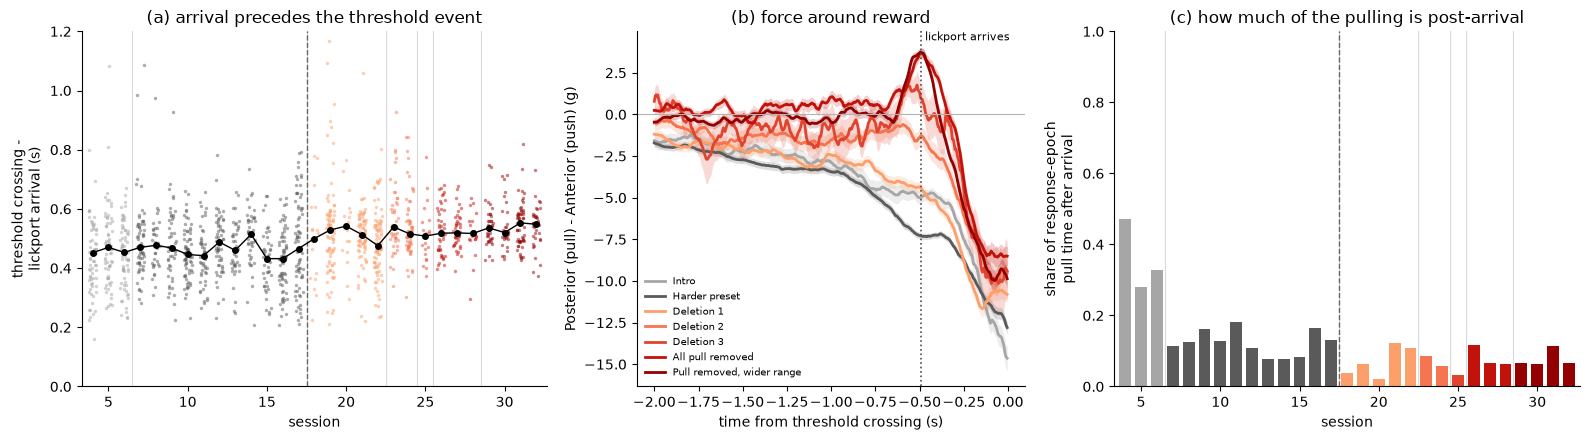

In [7]:
win = int(2.0 * FS)
t_al = np.arange(-win, 0) / FS
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw=dict(width_ratios=[1.2, 1, 1.2]))
ax = axes[0]
for s, g in trials_df.groupby('session'):
    ax.scatter(s + rng.uniform(-0.25, 0.25, len(g)), g['arrival_lag'], s=6, color=session_color[s], alpha=0.5, lw=0)
ax.plot(sess.index, trials_df.groupby('session')['arrival_lag'].median().reindex(sessions), 'o-', color='k', ms=4, lw=1)
ax.set_ylim(0, 1.2); ax.set_ylabel('threshold crossing -\nlickport arrival (s)'); ax.set_xlabel('session')
ax.set_title('(a) arrival precedes the threshold event'); mark_phases(ax, label=False); style(ax)

ax = axes[1]
for p, rg in PHASES:
    R = [r for r in resp if r['session'] in rg and len(r['pa']) >= win]
    if not R:
        continue
    M = np.vstack([r['pa'][-win:] for r in R])
    mu, se = M.mean(0), M.std(0) / np.sqrt(len(M))
    ax.plot(t_al, mu, color=PHASE_COLORS[p], lw=2, label=p)
    ax.fill_between(t_al, mu - se, mu + se, color=PHASE_COLORS[p], alpha=0.2, lw=0)
ax.axvline(-trials_df['arrival_lag'].median(), color='0.3', ls=':', lw=1.2)
ax.text(-trials_df['arrival_lag'].median(), 1.0, ' lickport arrives', transform=ax.get_xaxis_transform(), fontsize=8, va='top')
ax.axhline(0, color='0.7', lw=0.8)
ax.set_xlabel('time from threshold crossing (s)'); ax.set_ylabel('Posterior (pull) - Anterior (push) (g)')
ax.set_title('(b) force around reward'); ax.legend(frameon=False, fontsize=7, loc='lower left'); style(ax)

ax = axes[2]
pp = trials_df.groupby('session')[['n_pull', 'n_pull_post']].sum().reindex(sessions)
sess['pull_post_arrival_share'] = pp['n_pull_post'] / (pp['n_pull'] + pp['n_pull_post'])
ax.bar(sess.index, sess['pull_post_arrival_share'], color=[session_color[s] for s in sessions], width=0.75)
ax.set_ylim(0, 1); ax.set_ylabel('share of response-epoch\npull time after arrival'); ax.set_xlabel('session')
ax.set_title('(c) how much of the pulling is post-arrival'); mark_phases(ax, label=False); style(ax)
fig.tight_layout()
savefig(fig, '03_post_arrival_pull')
plt.show()

## 4. Where does the force go, compared with where reward is?
Rows = sessions (top = s4). x axis = **bearing**: centre (0 deg) = pull toward the mouse, edges (+/-180 deg) = push away.

* **(a)** lickport speed on the rewarded ring (at the ring's peak radius) for each direction. The dark centre
  is the deleted pull region; it grows until only the push half (edges) is yellow.
* **(b)** where the mouse's force points, as a fraction of *active* earning-window time (|F| >= 3 g), normalised per row.
  If the mouse had learned, the mass would move from the dark centre of (a) toward the yellow edges.
* **(c)** how hard it presses (|F| during active time), with the rewarded ring radii as dashed lines.
  A mouse that only shakes would show force spread across magnitudes rather than concentrated on the ring.

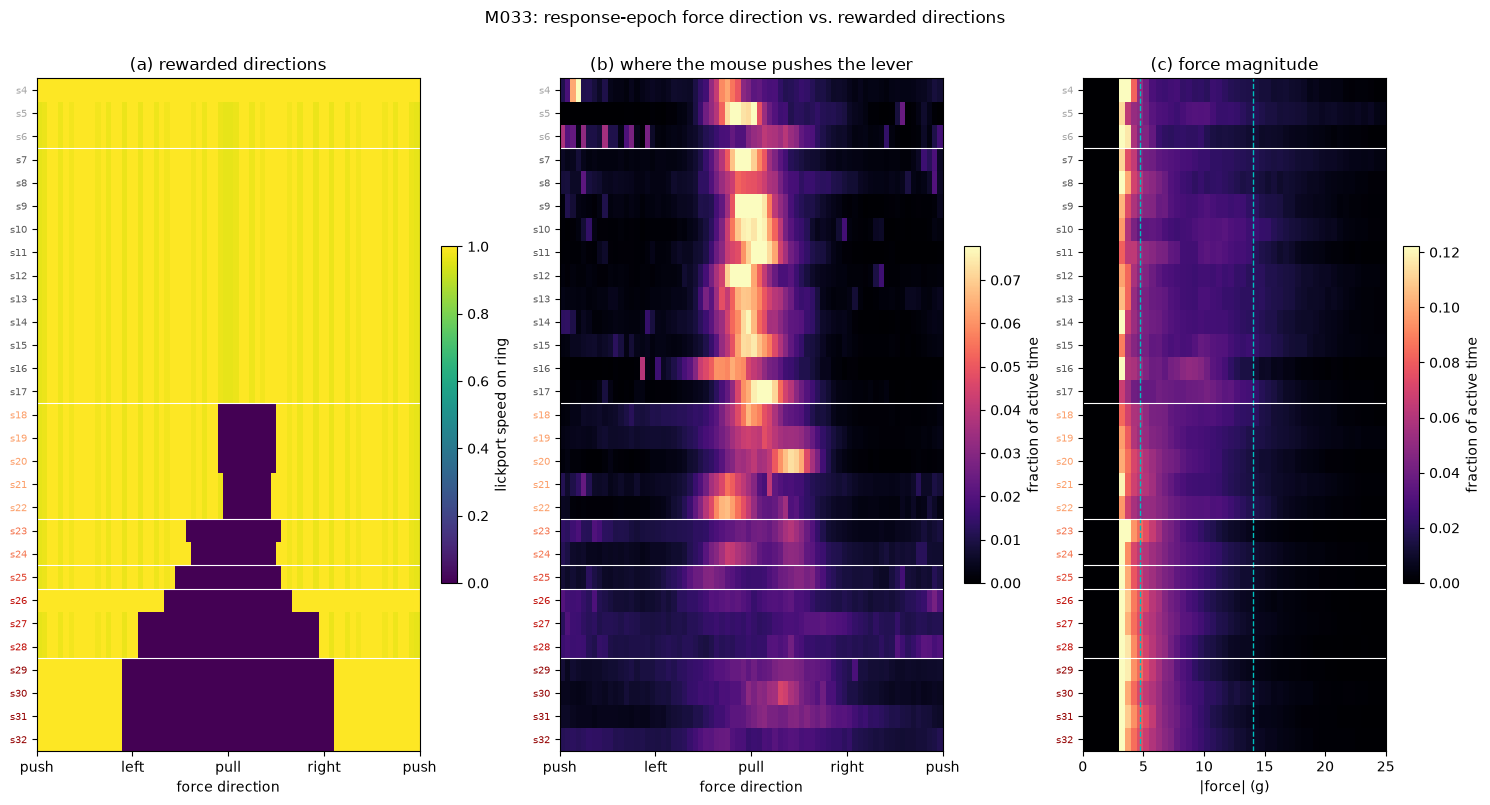

In [8]:
bear_bins = np.linspace(-180, 180, 73)
bear_ctr = (bear_bins[:-1] + bear_bins[1:]) / 2
mag_bins = np.linspace(0, 25, 51)

ring_map = np.zeros((len(sessions), len(bear_ctr)))
dir_occ = np.zeros_like(ring_map)
mag_occ = np.zeros((len(sessions), len(mag_bins) - 1))
for i, s in enumerate(sessions):
    L, ext = session_lut[s]
    th = np.deg2rad(bear_ctr)
    ring_map[i] = lut_lookup(L, ext, ring_r_peak * np.sin(th), -ring_r_peak * np.cos(th))
    lr = np.concatenate([pre(r)[0] for r in resp if r['session'] == s])
    pa = np.concatenate([pre(r)[1] for r in resp if r['session'] == s])
    mag = np.hypot(lr, pa); act = mag >= ACTIVE_G
    h, _ = np.histogram(bearing(lr[act], pa[act]), bear_bins); dir_occ[i] = h / h.sum()
    h, _ = np.histogram(mag[act], mag_bins); mag_occ[i] = h / h.sum()

def session_rows(ax):
    ax.set_yticks(range(len(sessions)))
    ax.set_yticklabels([f's{s}' for s in sessions], fontsize=7)
    for tl, s in zip(ax.get_yticklabels(), sessions):
        tl.set_color(session_color[s])
    for p, rg in PHASES[1:]:
        ax.axhline(sessions.index(rg[0]) - 0.5, color='w', lw=0.8)

def bearing_axis(ax):
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.set_xticklabels(['push', 'left', 'pull', 'right', 'push'])
    ax.set_xlabel('force direction')

fig, axes = plt.subplots(1, 3, figsize=(15, 8), gridspec_kw=dict(width_ratios=[1, 1, 0.8]))
im = axes[0].imshow(ring_map, aspect='auto', cmap='viridis', vmin=0, vmax=1,
                    extent=[-180, 180, len(sessions) - 0.5, -0.5])
fig.colorbar(im, ax=axes[0], label='lickport speed on ring', fraction=0.04)
axes[0].set_title('(a) rewarded directions')
im = axes[1].imshow(dir_occ, aspect='auto', cmap='magma', extent=[-180, 180, len(sessions) - 0.5, -0.5],
                    vmin=0, vmax=np.percentile(dir_occ, 99))
fig.colorbar(im, ax=axes[1], label='fraction of active time', fraction=0.04)
axes[1].set_title('(b) where the mouse pushes the lever')
im = axes[2].imshow(mag_occ, aspect='auto', cmap='magma', extent=[mag_bins[0], mag_bins[-1], len(sessions) - 0.5, -0.5],
                    vmin=0, vmax=np.percentile(mag_occ, 99))
for rr in (ring_r_in, ring_r_out):
    axes[2].axvline(rr, color='c', ls='--', lw=1)
fig.colorbar(im, ax=axes[2], label='fraction of active time', fraction=0.05)
axes[2].set_title('(c) force magnitude'); axes[2].set_xlabel('|force| (g)')
for ax in axes[:2]:
    bearing_axis(ax)
for ax in axes:
    session_rows(ax)
fig.suptitle(f'{subject_id}: response-epoch force direction vs. rewarded directions', y=1.0)
fig.tight_layout()
savefig(fig, '04_direction_heatmaps')
plt.show()

## 5. Time budget: resting vs. pulling vs. pushing
Trajectory plots draw every excursion with equal weight, regardless of how long the mouse spent there, so a
handful of brief pulls can dominate the picture. This figure quantifies the time spent instead.
* **(a)** fraction of the earning window (go -> lickport arrival) with any real force (|F| >= 3 g).
* **(b)** of that active time: share spent pulling / lateral / pushing.
* **(c)** rate of discrete excursions (|F| >= 5 g) per second of earning window, by direction.

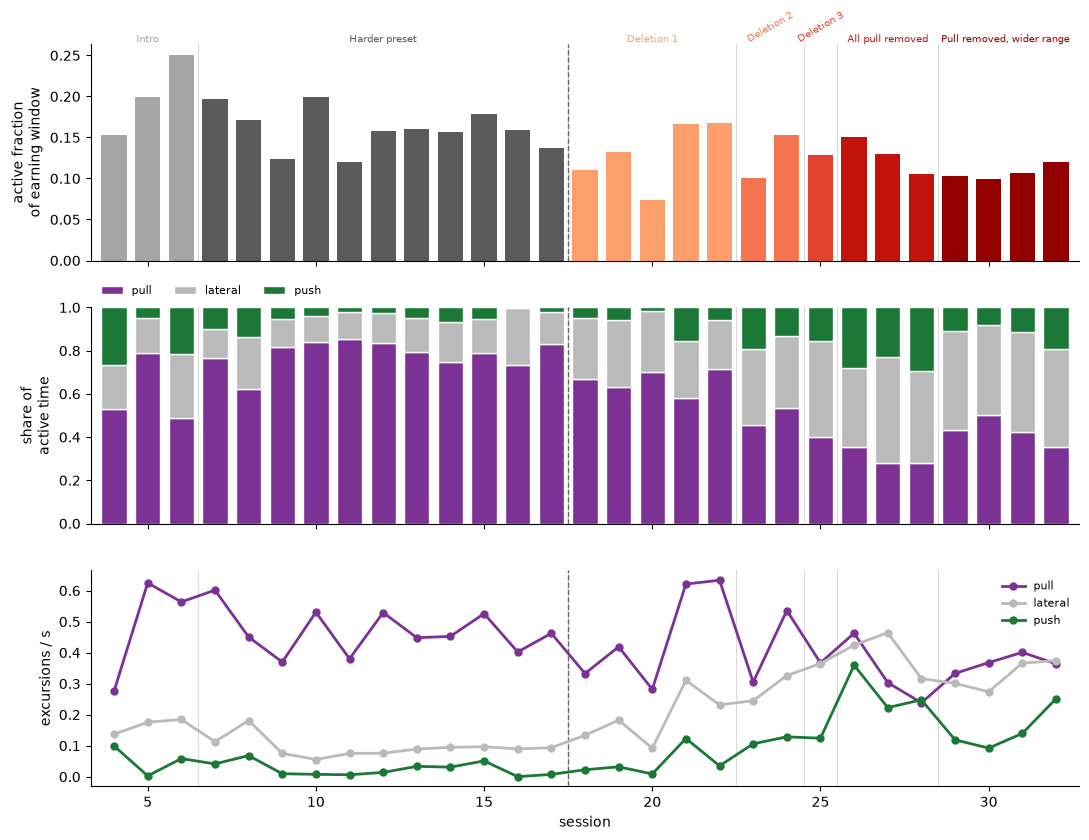

In [9]:
agg = trials_df.groupby('session')[['n', 'n_active', 'n_pull', 'n_push', 'n_lateral', 'exc_pull', 'exc_push', 'exc_lateral']].sum().reindex(sessions)
sess['active_frac'] = agg['n_active'] / agg['n']
for d in ('pull', 'lateral', 'push'):
    sess[f'{d}_share'] = agg[f'n_{d}'] / agg['n_active']
    sess[f'{d}_exc_per_s'] = agg[f'exc_{d}'] / (agg['n'] / FS)

fig, axes = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True)
ax = axes[0]
ax.bar(sess.index, sess['active_frac'], color=[session_color[s] for s in sessions], width=0.75)
ax.set_ylabel('active fraction\nof earning window'); mark_phases(ax)

ax = axes[1]
bottom = np.zeros(len(sessions))
for d in ('pull', 'lateral', 'push'):
    ax.bar(sess.index, sess[f'{d}_share'], bottom=bottom, color=DIR_COLORS[d], width=0.75, label=d,
           edgecolor='white', linewidth=1)
    bottom += sess[f'{d}_share'].values
ax.set_ylabel('share of\nactive time'); ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=8, ncol=3, loc='upper left', bbox_to_anchor=(0, 1.15))
mark_phases(ax, label=False)

ax = axes[2]
for d in ('pull', 'lateral', 'push'):
    ax.plot(sess.index, sess[f'{d}_exc_per_s'], 'o-', color=DIR_COLORS[d], lw=2, ms=5, label=d)
ax.set_ylabel('excursions / s'); ax.set_xlabel('session')
ax.legend(frameon=False, fontsize=8)
mark_phases(ax, label=False)
for a in axes: style(a)
fig.tight_layout()
savefig(fig, '05_time_budget')
plt.show()

## 6. Is the mouse's choice of direction better than random? (rotation null)
For every trial, rotate the whole force trajectory by 0, 15, ..., 345 deg (same magnitudes, same timing,
same shakiness, **only the direction is randomised**) and compute the lickport speed it would have produced
under that session's LUT.

* **(a)** actual mean lickport speed during the earning window (dots) vs. the random-direction null (grey: mean
  and 5-95 % range across rotations). The dashed line is a *habit replay*: the pre-deletion behaviour
  (s15-17) evaluated under each session's LUT, i.e. what the mouse would earn if it had changed nothing.
* **(b)** **direction index** = actual / mean null.
  * ~1: direction is irrelevant to what the mouse earns, which is what random shaking predicts.
  * <1: the mouse prefers *unrewarded* directions (still biased to the deleted pull zone).
  * >1: the mouse targets the rewarded directions (learning).

  Before s18 the ring is rotationally symmetric, so the index is 1 by construction (sanity check).

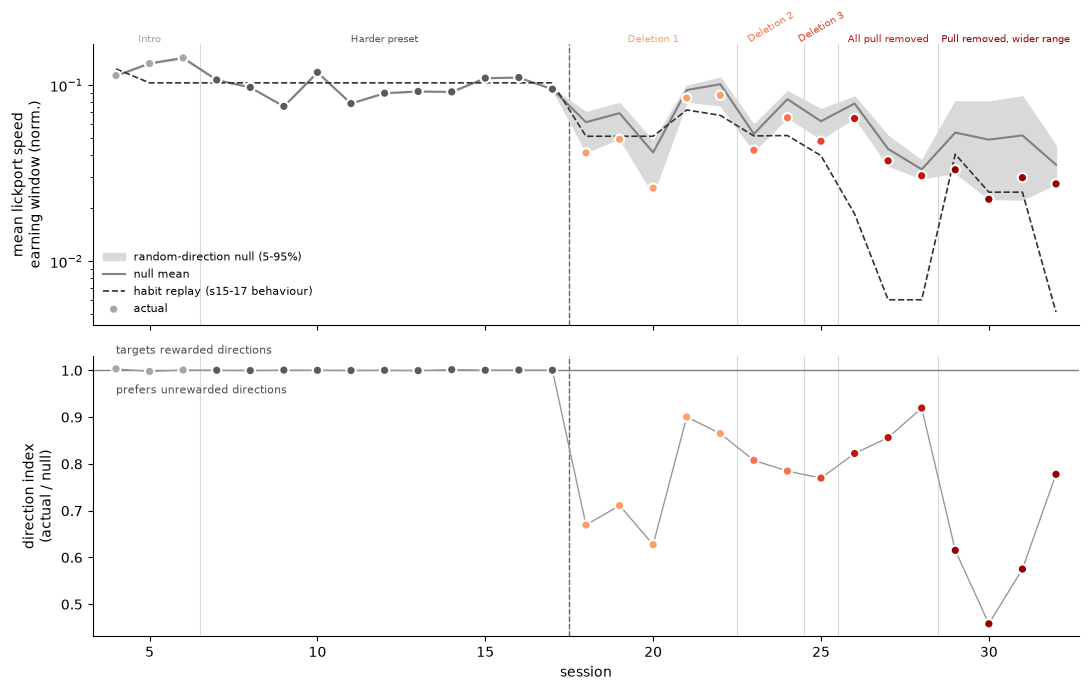

In [10]:
null_per_session = np.vstack(trials_df.groupby('session')['null_sums'].apply(lambda x: np.sum(np.vstack(x), axis=0)).reindex(sessions).values)
sess['speed_actual'] = trials_df.groupby('session')['v_sum'].sum().reindex(sessions) / agg['n']
null_mean = null_per_session / agg['n'].values[:, None]
sess['speed_null_mean'] = null_mean.mean(axis=1)
sess['speed_null_lo'], sess['speed_null_hi'] = np.percentile(null_mean, [5, 95], axis=1)
sess['direction_index'] = sess['speed_actual'] / sess['speed_null_mean']

base = [r for r in resp if r['session'] in (15, 16, 17)]
base_lr = np.concatenate([pre(r)[0] for r in base]); base_pa = np.concatenate([pre(r)[1] for r in base])
sess['speed_habit_replay'] = [lut_lookup(*session_lut[s], base_lr, base_pa).mean() for s in sessions]

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax = axes[0]
ax.fill_between(sess.index, sess['speed_null_lo'], sess['speed_null_hi'], color='0.85', label='random-direction null (5-95%)')
ax.plot(sess.index, sess['speed_null_mean'], color='0.5', lw=1.5, label='null mean')
ax.plot(sess.index, sess['speed_habit_replay'], '--', color='0.2', lw=1.2, label='habit replay (s15-17 behaviour)')
ax.scatter(sess.index, sess['speed_actual'], c=[session_color[s] for s in sessions], s=45, zorder=3,
           edgecolor='white', linewidth=1.5, label='actual')
ax.set_yscale('log'); ax.set_ylabel('mean lickport speed\nearning window (norm.)')
ax.legend(frameon=False, fontsize=8, loc='lower left')
mark_phases(ax)

ax = axes[1]
ax.axhline(1, color='0.5', lw=1)
ax.scatter(sess.index, sess['direction_index'], c=[session_color[s] for s in sessions], s=45, zorder=3,
           edgecolor='white', linewidth=1.5)
ax.plot(sess.index, sess['direction_index'], color='0.6', lw=1, zorder=2)
ax.text(sessions[0], 1.03, 'targets rewarded directions', fontsize=8, color='0.3', va='bottom')
ax.text(sessions[0], 0.97, 'prefers unrewarded directions', fontsize=8, color='0.3', va='top')
ax.set_ylabel('direction index\n(actual / null)'); ax.set_xlabel('session')
mark_phases(ax, label=False)
for a in axes: style(a)
fig.tight_layout()
savefig(fig, '06_rotation_null')
plt.show()

## 7. Initial movement vs. the movement that earned the reward
* **(a)** direction of the **first excursion** (|F| >= 5 g) after the go cue, as fraction of trials. This is the
  "default" or habitual action.
* **(b)** direction of the **rewarded bout** (the final stay in the rewarded zone). By construction it must lie in
  a rewarded direction. The question is whether it lies in a consistent one.
* **(c)** fraction of trials whose first excursion is a pull vs. a push.

If the mouse had learned "push now", the first move would switch from pull to push. If it shakes, the first move
stays habitual while the reward still comes from whatever direction happens to hit the ring.

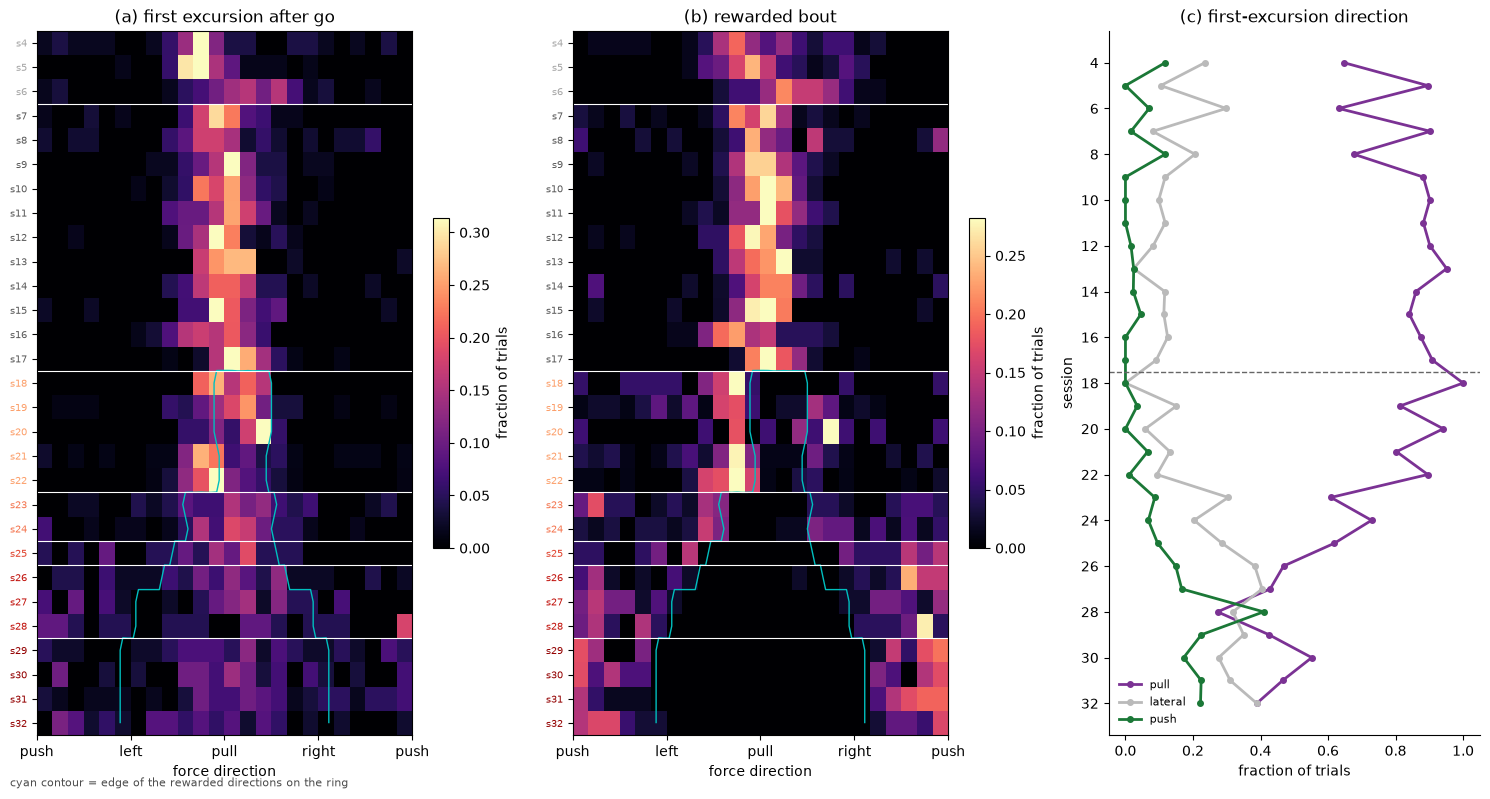

In [11]:
dir_bins = np.linspace(-180, 180, 25)
first_occ = np.zeros((len(sessions), len(dir_bins) - 1))
rew_occ = np.zeros_like(first_occ)
for i, s in enumerate(sessions):
    fb = trials_df.loc[trials_df.session == s, 'first_bearing'].dropna()
    h, _ = np.histogram(fb, dir_bins); first_occ[i] = h / max(h.sum(), 1)
    rb = bouts_df.loc[(bouts_df.session == s) & bouts_df.rewarded, 'bearing']
    h, _ = np.histogram(rb, dir_bins); rew_occ[i] = h / max(h.sum(), 1)

fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.9])
for k, (occ, title) in enumerate([(first_occ, '(a) first excursion after go'), (rew_occ, '(b) rewarded bout')]):
    ax = fig.add_subplot(gs[k])
    im = ax.imshow(occ, aspect='auto', cmap='magma', vmin=0, vmax=np.percentile(occ, 99),
                   extent=[-180, 180, len(sessions) - 0.5, -0.5])
    # outline rewarded directions on the ring
    ax.contour(bear_ctr, np.arange(len(sessions)), ring_map, levels=[ZONE_SPEED], colors='c', linewidths=1)
    fig.colorbar(im, ax=ax, fraction=0.04, label='fraction of trials')
    bearing_axis(ax); session_rows(ax); ax.set_title(title)

fb_sec = trials_df.dropna(subset=['first_bearing']).assign(sec=lambda d: sector(d.first_bearing.values))
frac = fb_sec.groupby('session')['sec'].value_counts(normalize=True).unstack(fill_value=0).reindex(sessions)
sess['first_pull_frac'], sess['first_push_frac'] = frac['pull'], frac['push']
ax = fig.add_subplot(gs[2])
for d in ('pull', 'lateral', 'push'):
    ax.plot(frac[d], sessions, 'o-', color=DIR_COLORS[d], label=d, lw=2, ms=4)
ax.invert_yaxis(); ax.set_yticks(sessions[::2]); ax.set_ylabel('session')
ax.axhline(17.5, color='0.4', ls='--', lw=1)
ax.set_xlabel('fraction of trials'); ax.set_title('(c) first-excursion direction'); ax.legend(frameon=False, fontsize=8)
style(ax)
fig.text(0.01, 0.01, 'cyan contour = edge of the rewarded directions on the ring', fontsize=8, color='0.3')
fig.tight_layout()
savefig(fig, '07_first_move_vs_rewarded_bout')
plt.show()

## 8. Rewarded-zone bouts: attempts, holds, and the rebound hypothesis
* **(a)** number of entries into the rewarded zone per rewarded trial. A mouse that shakes enters many times and
  fails (leaves before the lickport reaches the end). A mouse that has learned enters once and holds.
* **(b)** how long it stays in the zone: the final (rewarded) bout vs. the failed bouts. The gap between the two
  shows the hold the task requires; failed bouts far shorter than that are fly-throughs.
* **(c)** **rebound test**: fraction of zone entries preceded by a pull (PA < -5 g) within the last 300 ms. If
  the late-session pulls are a wind-up whose spring-back throws the lever into the anterior (rewarded) zone,
  the pulls would be functional rather than an unlearned habit.

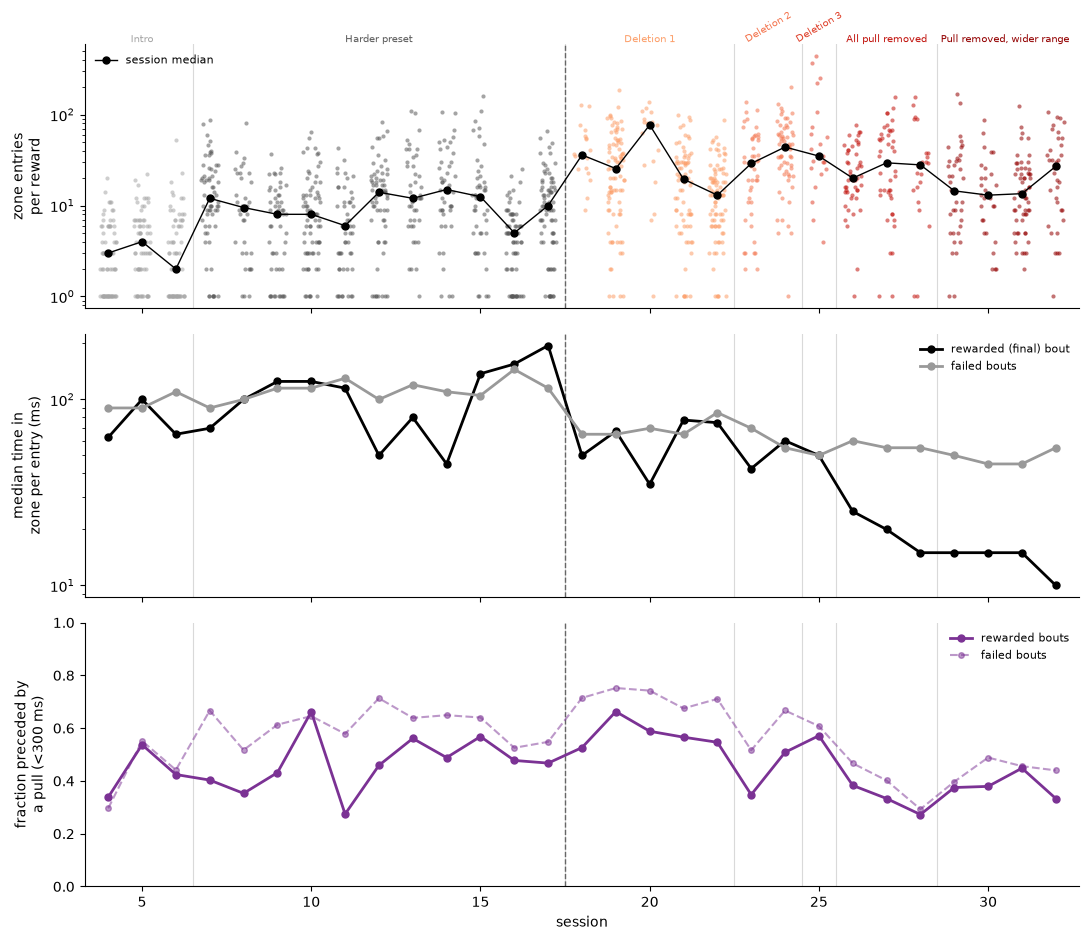

In [12]:
bsum = bouts_df.groupby(['session', 'rewarded']).agg(dur=('duration_ms', 'median'), pull_before=('pull_before', 'mean')).unstack().reindex(sessions)
sess['entries_per_reward_med'] = trials_df.groupby('session')['n_bouts'].median().reindex(sessions)
sess['rewarded_bout_ms'] = bsum[('dur', True)]
sess['failed_bout_ms'] = bsum[('dur', False)]
sess['rewarded_after_pull'] = bsum[('pull_before', True)]
sess['failed_after_pull'] = bsum[('pull_before', False)]

fig, axes = plt.subplots(3, 1, figsize=(11, 9.5), sharex=True)
ax = axes[0]
for s, g in trials_df.groupby('session'):
    ax.scatter(s + rng.uniform(-0.25, 0.25, len(g)), np.maximum(g['n_bouts'], 1), s=9, color=session_color[s], alpha=0.55, lw=0)
ax.plot(sess.index, sess['entries_per_reward_med'], 'o-', color='k', ms=5, lw=1, label='session median')
ax.set_yscale('log'); ax.set_ylabel('zone entries\nper reward'); ax.legend(frameon=False, fontsize=8, loc='upper left')
mark_phases(ax)

ax = axes[1]
ax.plot(sess.index, sess['rewarded_bout_ms'], 'o-', color='k', lw=2, ms=5, label='rewarded (final) bout')
ax.plot(sess.index, sess['failed_bout_ms'], 'o-', color='0.6', lw=2, ms=5, label='failed bouts')
ax.set_yscale('log'); ax.set_ylabel('median time in\nzone per entry (ms)')
ax.legend(frameon=False, fontsize=8); mark_phases(ax, label=False)

ax = axes[2]
ax.plot(sess.index, sess['rewarded_after_pull'], 'o-', color=DIR_COLORS['pull'], lw=2, ms=5, label='rewarded bouts')
ax.plot(sess.index, sess['failed_after_pull'], 'o--', color=DIR_COLORS['pull'], alpha=0.5, lw=1.5, ms=4, label='failed bouts')
ax.set_ylim(0, 1); ax.set_ylabel(f'fraction preceded by\na pull (<{PULL_LOOKBACK_S*1000:.0f} ms)')
ax.set_xlabel('session'); ax.legend(frameon=False, fontsize=8); mark_phases(ax, label=False)
for a in axes: style(a)
fig.tight_layout()
savefig(fig, '08_zone_bouts')
plt.show()

## 9. Example trajectories around reward
25 randomly chosen rewarded trials from the late pre-deletion sessions (s15-17) and from the last deletion
phase (s29-32), drawn on that period's reward map (grey = rewarded).
* Coloured line: the **last 1 s before lickport arrival** (dark -> yellow; yellow dot = arrival). This is the
  movement that earned the reward.
* Red line: **after arrival -> threshold crossing** (red x = threshold crossing). This is the post-arrival
  window from section 3.

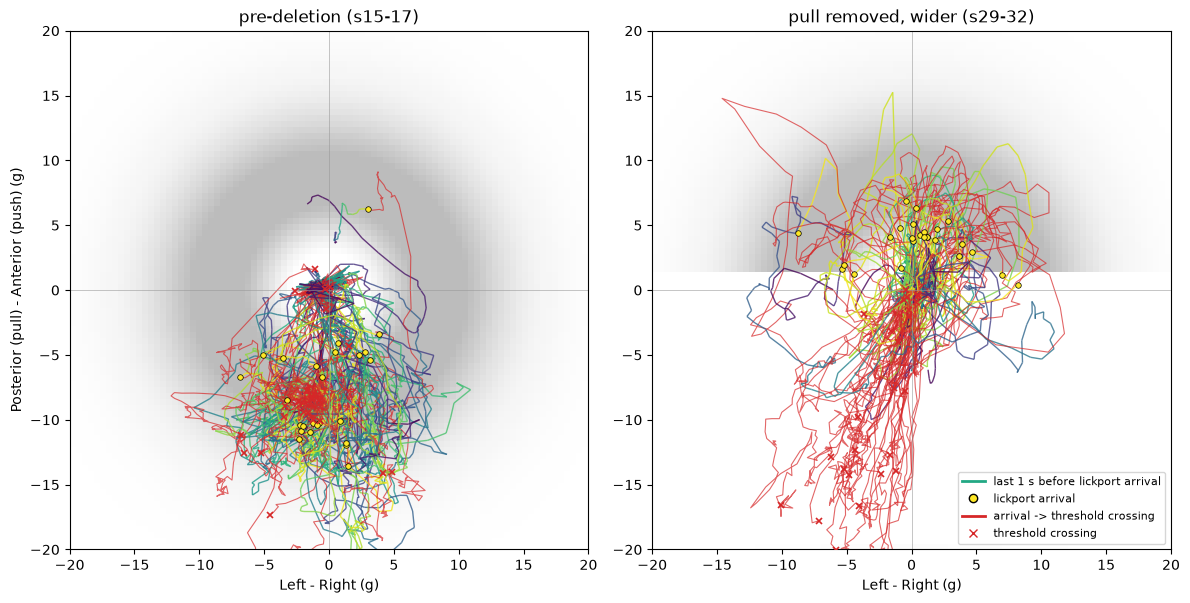

In [13]:
groups = [('pre-deletion (s15-17)', [15, 16, 17], 17), ('pull removed, wider (s29-32)', [29, 30, 31, 32], 32)]
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
lim = 20
for ax, (label, ss, lut_s) in zip(axes, groups):
    L, ext = session_lut[lut_s]
    ax.imshow(L.T, origin='lower', extent=ext, cmap='Greys', vmin=0, vmax=2.5, alpha=0.9)
    pool = [r for r in resp if r['session'] in ss]
    for idx in rng.choice(len(pool), size=min(25, len(pool)), replace=False):
        r = pool[idx]
        x, y = (a[-int(1.0 * FS):] for a in pre(r))
        seg = np.stack([np.column_stack([x[:-1], y[:-1]]), np.column_stack([x[1:], y[1:]])], axis=1)
        lc = LineCollection(seg, cmap='viridis', norm=plt.Normalize(0, len(x)), linewidths=1, alpha=0.8)
        lc.set_array(np.arange(len(x) - 1)); ax.add_collection(lc)
        ax.plot(x[-1], y[-1], 'o', color='#fde725', ms=4, mec='k', mew=0.5, zorder=4)
        px, py = post(r)
        if len(px):
            ax.plot(np.r_[x[-1], px], np.r_[y[-1], py], color='#d62728', lw=0.8, alpha=0.7)
            ax.plot(px[-1], py[-1], 'x', color='#d62728', ms=5, mew=1.2, zorder=4)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect('equal')
    ax.axhline(0, color='0.6', lw=0.4); ax.axvline(0, color='0.6', lw=0.4)
    ax.set_title(label); ax.set_xlabel('Left - Right (g)')
axes[0].set_ylabel('Posterior (pull) - Anterior (push) (g)')
handles = [Line2D([0], [0], color=plt.cm.viridis(0.6), lw=2, label='last 1 s before lickport arrival'),
           Line2D([0], [0], marker='o', ls='None', color='#fde725', mec='k', label='lickport arrival'),
           Line2D([0], [0], color='#d62728', lw=2, label='arrival -> threshold crossing'),
           Line2D([0], [0], marker='x', ls='None', color='#d62728', label='threshold crossing')]
axes[1].legend(handles=handles, frameon=True, fontsize=8, loc='lower right')
fig.tight_layout()
savefig(fig, '09_trajectories_around_reward')
plt.show()

## 10. Within-session dynamics
Each session's rewarded trials are split into 5 equal chunks in order (columns). This shows whether the mouse
adapts *within* a session (e.g. starts pulling, then switches to pushing once pulls stop paying) even if it
resets between sessions.
* **(a)** pull share of active time. **(b)** median time to reward (log).

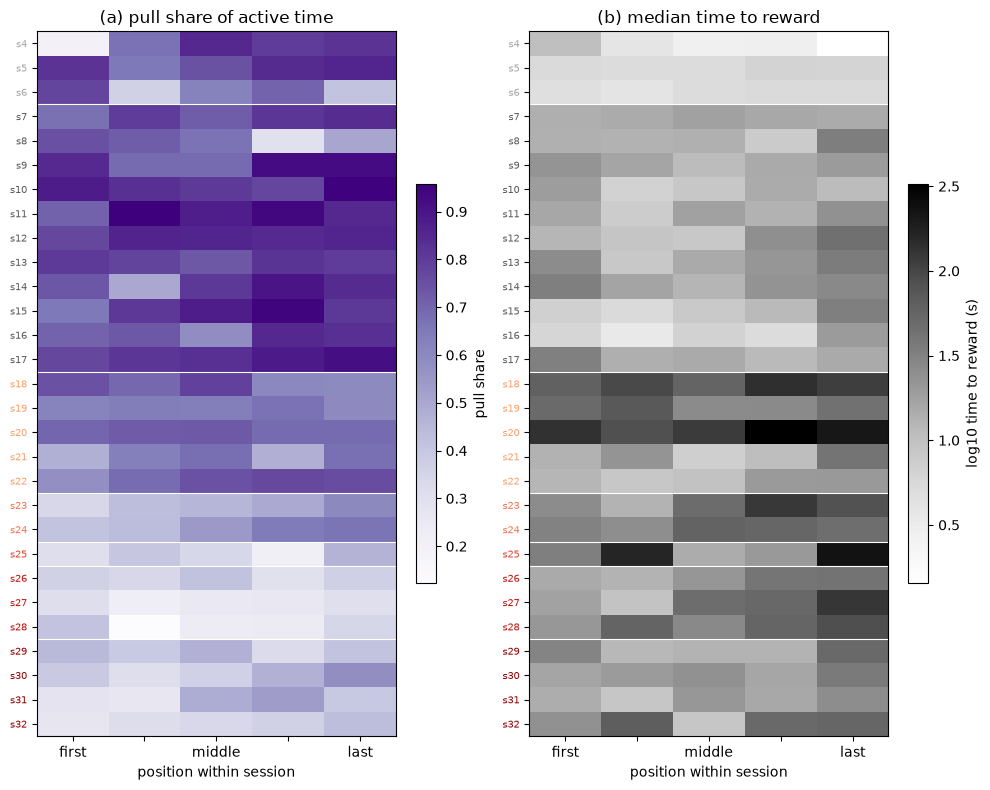

In [14]:
n_q = 5
trials_df['chunk'] = trials_df.groupby('session')['trial'].transform(lambda t: pd.qcut(t.rank(method='first'), n_q, labels=False))
wq = trials_df.groupby(['session', 'chunk']).agg(n_pull=('n_pull', 'sum'), n_active=('n_active', 'sum'), t2r=('t2r', 'median'))
pull_q = (wq['n_pull'] / wq['n_active']).unstack().reindex(sessions)
t2r_q = np.log10(wq['t2r']).unstack().reindex(sessions)

fig, axes = plt.subplots(1, 2, figsize=(10, 8))
for ax, mat, title, cmap, lab in [(axes[0], pull_q, '(a) pull share of active time', 'Purples', 'pull share'),
                                  (axes[1], t2r_q, '(b) median time to reward', 'Greys', 'log10 time to reward (s)')]:
    im = ax.imshow(mat.values, aspect='auto', cmap=cmap, extent=[-0.5, n_q - 0.5, len(sessions) - 0.5, -0.5])
    fig.colorbar(im, ax=ax, fraction=0.05, label=lab)
    ax.set_xticks(range(n_q)); ax.set_xticklabels(['first', '', 'middle', '', 'last'])
    ax.set_xlabel('position within session'); ax.set_title(title)
    session_rows(ax)
fig.tight_layout()
savefig(fig, '10_within_session')
plt.show()

## 11. Summary table and trends across the deletion sessions (s18-32)
Spearman correlation of each per-session metric with session number, restricted to the deletion sessions.
There are only 15 sessions, so read the p-values as descriptive, not confirmatory.

In [15]:
cols = ['n_rewards', 't2r_med', 'pull_post_arrival_share', 'rewards_per_min', 'quiescence_med', 'active_frac', 'pull_share', 'push_share',
        'pull_exc_per_s', 'push_exc_per_s', 'direction_index', 'first_pull_frac', 'first_push_frac',
        'entries_per_reward_med', 'rewarded_bout_ms', 'failed_bout_ms', 'rewarded_after_pull']
summary = sess[cols].copy()
summary.insert(0, 'phase', [session_phase[s] for s in sessions])
display(summary.round(3))

del_s = [s for s in sessions if s >= 18]
trend = pd.DataFrame([dict(metric=c, **dict(zip(['spearman_rho', 'p'], spearmanr(del_s, sess.loc[del_s, c], nan_policy='omit'))))
                      for c in cols]).set_index('metric')
summary.to_csv(fig_dir / f'{subject_id}_session_summary.csv')
trend.round(3)

,phase,n_rewards,t2r_med,pull_post_arrival_share,rewards_per_min,quiescence_med,active_frac,pull_share,push_share,pull_exc_per_s,push_exc_per_s,direction_index,first_pull_frac,first_push_frac,entries_per_reward_med,rewarded_bout_ms,failed_bout_ms,rewarded_after_pull
session,,,,,,,,,,,,,,,,,,
4,Intro,75,3.290,0.472,3.265,1.758,0.153,0.529,0.265,0.276,0.099,1.003,0.647,0.118,3.0,62.5,90.0,0.338
5,Intro,67,5.392,0.280,4.275,0.714,0.200,0.789,0.048,0.625,0.003,0.998,0.896,0.000,4.0,100.0,90.0,0.537
6,Intro,70,5.144,0.328,4.928,0.862,0.251,0.489,0.218,0.563,0.058,1.001,0.632,0.070,2.0,65.0,110.0,0.424
7,Harder preset,63,14.990,0.115,2.122,0.728,0.197,0.765,0.100,0.601,0.041,1.000,0.903,0.016,12.0,70.0,90.0,0.403
8,Harder preset,34,13.352,0.125,2.199,0.959,0.172,0.621,0.135,0.450,0.068,1.000,0.676,0.118,9.5,100.0,100.0,0.353
9,Harder preset,51,14.756,0.161,2.303,0.682,0.124,0.817,0.052,0.370,0.009,1.000,0.882,0.000,8.0,125.0,115.0,0.431
10,Harder preset,71,10.016,0.127,2.697,0.692,0.199,0.840,0.039,0.530,0.008,1.000,0.901,0.000,8.0,125.0,115.0,0.662
11,Harder preset,51,14.436,0.182,2.475,0.684,0.120,0.853,0.020,0.380,0.006,1.000,0.882,0.000,6.0,115.0,130.0,0.275
12,Harder preset,61,12.706,0.108,1.894,0.694,0.158,0.837,0.026,0.529,0.014,1.000,0.902,0.016,14.0,50.0,100.0,0.459


,spearman_rho,p
metric,,
n_rewards,-0.116,0.680
t2r_med,-0.243,0.383
pull_post_arrival_share,0.246,0.376
rewards_per_min,0.007,0.980
quiescence_med,0.527,0.044
active_frac,-0.268,0.334
pull_share,-0.714,0.003
push_share,0.507,0.054
pull_exc_per_s,-0.121,0.666


## Findings (M033, sessions 4-32)

**1. Time to reward got worse at deletion onset and never recovered.** The median time to reward rose from ~6-20 s
(s7-17) to ~15-150 s, and the reward rate dropped from ~2-3 to ~0.3-1.5 rewards/min. There is no trend across
s18-32 (Spearman rho = -0.24, p = 0.4). Time to reward alone therefore says "no learning". It is a coarse measure,
though: the LUT changed between sessions, and the mouse can get faster through luck as well as skill.

**2. The mouse *did* change its behaviour, consistently and in the right direction.** Within the earning window
(go -> lickport arrival):
* pull share of active time: ~0.8 pre-deletion -> ~0.35-0.45 at the end (rho = -0.71, p = 0.003)
* push excursions: ~0.01/s -> ~0.1-0.35/s (rho = 0.69, p = 0.005)
* first move after go: pull on ~90 % of trials pre-deletion -> ~40 %; push 0 % -> ~20-40 % (rho = 0.92, p < 0.001)
* relative to the *habit replay* (fig. 6, dashed line), the mouse earns 3-5x more than it would have by keeping
  its s15-17 behaviour.

So the mouse is not simply blind to the deletion: it suppressed the default pull and added pushes.

**3. But it did not learn to *target* the rewarded directions.** The direction index stays below 1 in every
deletion session and does not trend upward (fig. 6): the directions the mouse picks pay *less* than randomly
rotated versions of the same movements. Pull is still the single most common direction (~40 % of active time)
even though it has paid nothing since s26. Force direction in late sessions is spread broadly around the circle
(fig. 4b) rather than concentrated in the rewarded anterior half.

**4. How rewards are actually earned late in training: weak, brief brushes of the ring's inner edge.** The force is
mostly 3-5 g (fig. 4c), right at the inner edge of the ring (~4.7 g). The mouse enters the rewarded zone 13-30 times
per reward (vs. 5-15 pre-deletion), and the entry that finally brings the lickport out is short (fig. 8). In
fig. 9 the arrivals cluster at +3 to +6 g anterior. This looks like low-amplitude, variable jiggling that is biased
away from straight pulls and occasionally crosses into the anterior ring, rather than a deliberate push-and-hold.

**5. Much of the late-session "pulling" you see in trajectory plots happens after the reward is earned.** Every
trial ends with a ~0.5 s window between lickport arrival and the threshold-crossing event, in which the mouse pulls
hard toward itself (fig. 3), most likely reaching for the spout. Use go -> lickport arrival as the response window
when asking what the mouse does to earn the reward.

**Bottom line:** your intuition is partly right. The mouse never acquired a targeted "push forward" strategy, and
rewards are largely obtained by variable low-force movement. But it is not *pure* random shaking either: the default
pull was progressively suppressed, the first move shifted toward pushing, and the behaviour moved well away from the
old habit. This looks like a mouse whose old strategy was extinguished and that is exploring, without having found
the new contingency. Possible next steps:
* shape the push explicitly (e.g. a lower-force anterior target, or a ring whose anterior part starts closer to zero);
* check whether the post-arrival pull is a reach/lick movement using the lick events or video;
* repeat this notebook on another mouse that went through deletion, for comparison.